<a href="https://colab.research.google.com/github/ashwinkck/SME-1-/blob/main/upes/GenAI/UPES_genai_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Generative vs Discriminative models comparison**




In [ ]:
!pip install numpy matplotlib scikit-learn

how are we gonna implement?
*   1)Dataset Generation
*   2)Data Visualization




*   3)Model training
*   4)Model comparison
*   5)Synthetic data Generation

1) Importing the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs # Generates a synthetic datasets containing clusters
from sklearn.model_selection import train_test_split

from sklearn.naive_bayes import GaussianNB # implements guassian naive bayes - a prob classifier
from sklearn.linear_model import LogisticRegression # implementing discriminative classifier
from sklearn.metrics import accuracy_score # measures predictions correct or not

2. Creating our Dataset

In [2]:
X, y = make_blobs(
    n_samples=1000, #generating 1000 samples
    centers=2, # creating 2 clusters
    n_features=2, # sample with 2 features
    cluster_std=1.6, # controls how spread out the clusters are
    random_state=42 #makes the experiment reproducable
)

print("Dataset shape:",X.shape)
print("Labels shape:",y.shape)

Dataset shape: (1000, 2)
Labels shape: (1000,)


3. Visualizing the dataset

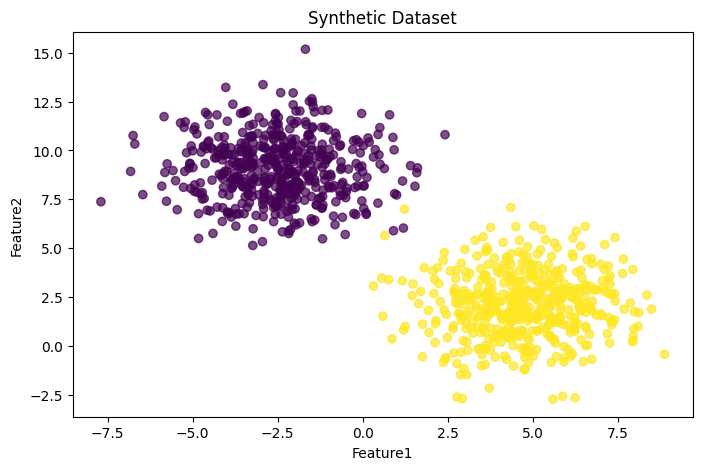

In [3]:
plt.figure(figsize=(8,5))

plt.scatter(
    X[:,0],
    X[:,1],
    c=y,
    cmap="viridis",
    alpha=0.7
)
plt.xlabel("Feature1")
plt.ylabel("Feature2")
plt.title("Synthetic Dataset")
plt.show()

4.Split the Dataset

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, #using 20% for training
    random_state = 42
)
print("Training samples:",len(X_train))
print("Testing Samples:",len(X_test))

Training samples: 800
Testing Samples: 200


5.Build the generative model

In [6]:
generative_model = GaussianNB()
generative_model.fit(X_train,y_train)

generative_predictions = generative_model.predict(X_test)

generative_accuracy = accuracy_score(
    y_test,
    generative_predictions
)
print("Generative model accuracy:",generative_accuracy)

Generative model accuracy: 1.0


6 - Building the Discriminative model

In [7]:
discriminative_model = LogisticRegression()
discriminative_model.fit(X_train,y_train)
discriminative_predictions = (
    discriminative_model.predict(X_test)
)
discriminative_accuracy = accuracy_score(
    y_test,
    discriminative_predictions
)
print("Discriminative Model Accuracy:",discriminative_accuracy)

Discriminative Model Accuracy: 1.0


P(Y|X) - Discriminative model

7.Comparing the results

In [8]:
print("Model Comparison")

print("-----------------------")

print("Gaussian Naive Bayes:",generative_accuracy)

print("Logistic Regression:",discriminative_accuracy)

Model Comparison
-----------------------
Gaussian Naive Bayes: 1.0
Logistic Regression: 1.0




*   Gaussian Naive bayes(generative modeling) - Class conditional distributions
*   Logistic regression(Discriminative modeling) - relationship between i/p features and class prob



8. Generating new synthetic samples

In [9]:
class_index = 0
mean = generative_model.theta_[class_index] #theta - contains learned class-wise feature means
variance = generative_model.var_[class_index] # Variance - contains corresponding feature variances

synthetic_samples = np.random.normal(
    loc=mean,
    scale = np.sqrt(variance),
    size=(100,2)
)
print("Generated samples:")
print(synthetic_samples[:5])

Generated samples:
[[-1.70281883 12.1026582 ]
 [-2.27840359 11.15515939]
 [-4.04765449 10.53064785]
 [ 0.11690921  8.77127056]
 [-2.20751453  6.77984578]]


9. Visualize the generated samples

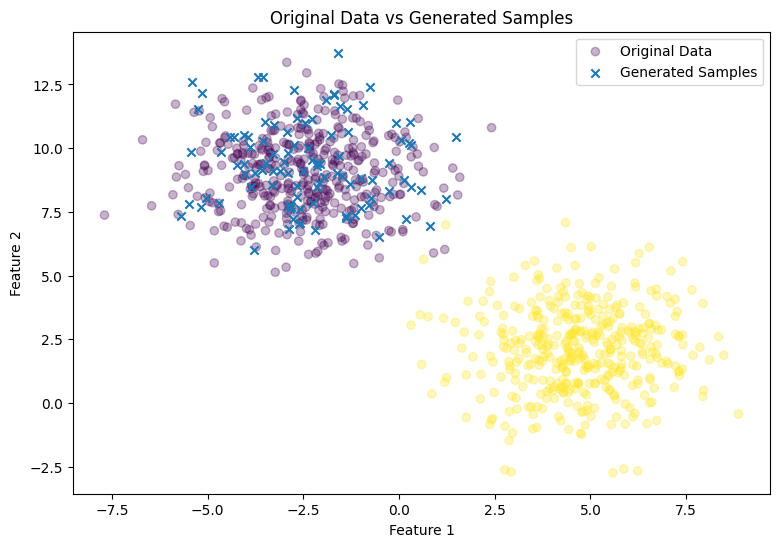

In [10]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    alpha=0.3,
    label="Original Data"
)

plt.scatter(
    synthetic_samples[:, 0],
    synthetic_samples[:, 1],
    marker="x",
    label="Generated Samples"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.title("Original Data vs Generated Samples")

plt.legend()
plt.show()